# IEEE-118: independent evaluation scenarios for PF and masked-voltage SE

This notebook loads the fine-tuned 250,000-scenario IEEE-118 **PowerFlow** checkpoint and its saved normalizer from [gridfm/genco-pf-transfer](https://huggingface.co/gridfm/genco-pf-transfer). It evaluates the two locally generated datasets in `datakit_out` and `datakit_out_aged`; it does not download or use the Hugging Face evaluation data. Each dataset is evaluated twice:

- **PF:** Graphkit's PowerFlow task transform applies the checkpoint's standard power-flow masks.
- **SE:** the same PF checkpoint estimates voltages after 30% of bus `Vm` and 30% of bus `Va` measurements are hidden independently. Other bus, generator, and branch measurements remain available, as in the previous masked-voltage experiment. This is a measurement-masking experiment, not a separately trained state-estimation model or Graphkit's noisy StateEstimation task.

The standard runs save one row per bus with dataset and scenario identity, ground truth, raw model predictions, and voltage-mask flags. `Vm` is in p.u., `Va` in degrees, and `Pg`/`Qg` in MW/Mvar. Predictions for known (unmasked) values are saved as emitted by the model; they are not replaced with ground truth. Later sections compare the signed-error distributions and evaluate hidden aging, where the model receives original line impedances for aged-network observations.

Run from this repository's root or `src/` directory in the provided environment. The first run downloads only the model artifacts and may build Graphkit's processed dataset caches. Parquet outputs and histogram PNGs are written under `src/results/local_predictions/`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import torch
import yaml
from huggingface_hub import hf_hub_download
from torch_geometric.data import Batch
from tqdm.auto import tqdm

from gridfm_graphkit.cli import _normalize_loaded_state_dict_keys
from gridfm_graphkit.datasets.globals import (
    B_ON,
    C0_H,
    C2_H,
    G_ON,
    PQ_H,
    PV_H,
    REF_H,
    VA_H,
    VM_H,
    PG_OUT,
    QG_OUT,
    VA_OUT,
    VM_OUT,
    YFF_TT_R,
    YFT_TF_I,
    QG_H,
)
from gridfm_graphkit.datasets.powergrid_hetero_dataset import HeteroGridDatasetDisk
from gridfm_graphkit.datasets.transforms import (
    RemoveInactiveBranches,
    RemoveInactiveGenerators,
)
from gridfm_graphkit.io.param_handler import (
    NestedNamespace,
    get_task_transforms,
    load_model,
    load_normalizer,
)

MODEL_REPO_ID = "gridfm/genco-pf-transfer"
MODEL_REVISION = "main"
RUN_DIR = Path("finetune/case118_250000")
PROJECT_DIR = Path(".")
NORMALIZER_NETWORK = "case118_ieee"
DATASET_ROOTS = {
    "case118_original": PROJECT_DIR / "datakit_out" / "case118_original",
    "case118_aged": PROJECT_DIR / "datakit_out_aged" / "case118_aged",
}
OUTPUT_DIR = PROJECT_DIR / "results" / "local_predictions"
BATCH_SIZE = 16
SEED = 42
SE_MASK_FRACTION = 0.10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Inference device: {DEVICE}")

Inference device: cuda


## 1. Load the matched model artifacts and local datasets

The checkpoint, YAML, and normalizer come from the same fine-tuning run. The evaluation data come exclusively from the locally generated `datakit_out/case118_original` and `datakit_out_aged/case118_aged` directories. The aged network uses the IEEE-118 normalizer because it has the same feature schema and topology dimensions.


In [2]:
artifact_paths = {
    key: hf_hub_download(
        MODEL_REPO_ID,
        f"{RUN_DIR}/{filename}",
        revision=MODEL_REVISION,
    )
    for key, filename in {
        "checkpoint": "best_model_state_dict.pt",
        "config": "case118_250000.yaml",
        "normalizer": "normalizer_stats.pt",
    }.items()
}
print(f"{artifact_paths = }")
with open(artifact_paths["config"], encoding="utf-8") as handle:
    args = NestedNamespace(**yaml.safe_load(handle))

saved_stats = torch.load(
    artifact_paths["normalizer"],
    map_location="cpu",
    weights_only=True,
)
normalizer = load_normalizer(args)
normalizer.fit_from_dict(saved_stats[NORMALIZER_NETWORK])

required_tables = ["bus_data.parquet", "gen_data.parquet", "branch_data.parquet"]
for dataset_name, root in DATASET_ROOTS.items():
    missing = [name for name in required_tables if not (root / "raw" / name).exists()]
    if missing:
        raise FileNotFoundError(f"{dataset_name} is missing raw tables: {missing}")

datasets = {
    dataset_name: HeteroGridDatasetDisk(
        root=str(root),
        data_normalizer=normalizer,
        transform=None,
        stream_partitions=getattr(args.data, "stream_partitions", "auto"),
    )
    for dataset_name, root in DATASET_ROOTS.items()
}

model = load_model(args)
state = torch.load(
    artifact_paths["checkpoint"],
    map_location="cpu",
    weights_only=True,
)
state = _normalize_loaded_state_dict_keys(state)
model.load_state_dict(
    {key.removeprefix("model."): value for key, value in state.items()},
    strict=True,
)
model.to(DEVICE).eval()
for dataset_name, dataset in datasets.items():
    print(
        f"Loaded {len(dataset):,} scenarios from {DATASET_ROOTS[dataset_name] / 'raw'}"
    )

artifact_paths = {'checkpoint': '/home/aj/.cache/huggingface/hub/models--gridfm--genco-pf-transfer/snapshots/45bcde49af8e0767074790e48af8e7babf06f0c0/finetune/case118_250000/best_model_state_dict.pt', 'config': '/home/aj/.cache/huggingface/hub/models--gridfm--genco-pf-transfer/snapshots/45bcde49af8e0767074790e48af8e7babf06f0c0/finetune/case118_250000/case118_250000.yaml', 'normalizer': '/home/aj/.cache/huggingface/hub/models--gridfm--genco-pf-transfer/snapshots/45bcde49af8e0767074790e48af8e7babf06f0c0/finetune/case118_250000/normalizer_stats.pt'}
Loaded 1,000 scenarios from datakit_out/case118_original/raw
Loaded 1,000 scenarios from datakit_out_aged/case118_aged/raw


In [3]:
print(model)

GNS_heterogeneous(
  (input_proj_bus): Sequential(
    (0): Linear(in_features=15, out_features=48, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=48, out_features=48, bias=True)
    (3): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  )
  (input_proj_gen): Sequential(
    (0): Linear(in_features=6, out_features=48, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=48, out_features=48, bias=True)
    (3): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  )
  (input_proj_edge): Sequential(
    (0): Linear(in_features=10, out_features=48, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=48, out_features=48, bias=True)
    (3): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  )
  (physics_mlp): Sequential(
    (0): Linear(in_features=2, out_features=384, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
  )
  (layers): ModuleList(
    (0-11): 12 x HeteroConv(num_relations=3)
  )
 

## 2. Define PF and SE inputs

PF uses Graphkit's registered PowerFlow transform, including removal of inactive equipment and the task's standard masks. For SE, inactive equipment is removed first; a fixed seed derived from each dataset index chooses the hidden voltage measurements. The target `y` tensors are preserved before input masking. The per-scenario seed makes SE masks independent of batch size and execution order.


In [4]:
pf_transform = get_task_transforms(args)
remove_branches = RemoveInactiveBranches()
remove_generators = RemoveInactiveGenerators()
mask_value = float(args.data.mask_value)


def apply_task_transform(graph, index, task):
    if task == "pf":
        return pf_transform(graph)
    if task != "se":
        raise ValueError(f"Unknown task: {task}")

    graph = remove_generators(remove_branches(graph))
    bus_x = graph["bus"].x
    n_bus = bus_x.size(0)
    n_mask = max(1, round(SE_MASK_FRACTION * n_bus))
    rng = np.random.default_rng(np.random.SeedSequence([SEED, int(index)]))
    bus_mask = torch.zeros_like(bus_x, dtype=torch.bool)
    bus_mask[torch.as_tensor(rng.choice(n_bus, n_mask, replace=False)), VM_H] = True
    bus_mask[torch.as_tensor(rng.choice(n_bus, n_mask, replace=False)), VA_H] = True
    graph.mask_dict = {
        "bus": bus_mask,
        "PQ": bus_x[:, PQ_H] == 1,
        "PV": bus_x[:, PV_H] == 1,
        "REF": bus_x[:, REF_H] == 1,
        "gen": torch.zeros_like(graph["gen"].x, dtype=torch.bool),
        "branch": torch.zeros_like(
            graph["bus", "connects", "bus"].edge_attr,
            dtype=torch.bool,
        ),
    }
    bus_x[bus_mask] = mask_value
    return graph


def prepare_graph(dataset, index, task):
    return apply_task_transform(dataset[index], index, task)

In [5]:
prepare_graph(datasets["case118_original"], 0, "pf")

HeteroData(
  scenario_id=[1],
  baseMVA=137.93067932128906,
  is_normalized=True,
  mask_dict={
    bus=[118, 15],
    gen=[54, 6],
    branch=[372, 10],
    PQ=[118],
    PV=[118],
    REF=[118],
  },
  bus={
    x=[118, 15],
    static=[118, 5],
    y=[118, 5],
  },
  gen={
    x=[54, 6],
    y=[54, 1],
  },
  (bus, connects, bus)={
    edge_index=[2, 372],
    edge_attr=[372, 10],
    static=[372, 3],
    y=[372, 2],
  },
  (gen, connected_to, bus)={ edge_index=[2, 54] },
  (bus, connected_to, gen)={ edge_index=[2, 54] }
)

In [6]:
prepare_graph(datasets["case118_aged"], 0, "se")

HeteroData(
  scenario_id=[1],
  baseMVA=137.93067932128906,
  is_normalized=True,
  mask_dict={
    bus=[118, 15],
    PQ=[118],
    PV=[118],
    REF=[118],
    gen=[54, 6],
    branch=[372, 10],
  },
  bus={
    x=[118, 15],
    static=[118, 5],
    y=[118, 5],
  },
  gen={
    x=[54, 6],
    y=[54, 1],
  },
  (bus, connects, bus)={
    edge_index=[2, 372],
    edge_attr=[372, 10],
    static=[372, 3],
    y=[372, 2],
  },
  (gen, connected_to, bus)={ edge_index=[2, 54] },
  (bus, connected_to, gen)={ edge_index=[2, 54] }
)

## 3. Predict every scenario and write ground truth with predictions

Rows are streamed to Parquet one batch at a time to avoid retaining the full output in memory. The `dataset_name`, `dataset_index`, `scenario_id`, and zero-based `bus_index` columns identify every row. `vm_masked` and `va_masked` tell which voltage values were unavailable to the model. The checkpoint's bus head also emits `Pg` and `Qg`; their ground truths are aggregate generator `Pg` at each bus and the bus `Qg` label.


In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def predict_all(
    dataset_name,
    dataset,
    task,
    indices=None,
    graph_preparer=prepare_graph,
):
    if indices is None:
        indices = range(len(dataset))
    indices = list(indices)
    output_path = OUTPUT_DIR / f"{dataset_name}_{task}_ground_truth_predictions.parquet"
    temp_path = output_path.with_suffix(".tmp.parquet")
    writer = None
    rows_written = 0
    seen_scenarios = set()
    with torch.inference_mode():
        for start in tqdm(
            range(0, len(indices), BATCH_SIZE),
            desc=f"{dataset_name} {task.upper()}",
        ):
            batch_indices = indices[start : start + BATCH_SIZE]
            graphs = [graph_preparer(dataset, index, task) for index in batch_indices]
            batch = Batch.from_data_list(graphs).to(DEVICE)
            output = model(batch)
            pred = output["bus"]
            if pred.size(1) <= max(VM_OUT, VA_OUT, PG_OUT, QG_OUT):
                raise ValueError("Model bus output does not contain Vm, Va, Pg and Qg")

            # Graphkit keeps Va in radians during inverse_transform.
            normalizer.inverse_output(output, batch)
            normalizer.inverse_transform(batch)
            bus_y = batch["bus"].y
            gen_y = batch["gen"].y
            gen_to_bus = batch["gen", "connected_to", "bus"].edge_index[1]
            pg_target = torch.zeros(
                bus_y.size(0),
                device=DEVICE,
                dtype=gen_y.dtype,
            )
            pg_target.index_add_(0, gen_to_bus, gen_y[:, 0])

            ptr = batch["bus"].ptr.cpu().tolist()
            frames = []
            for j, index in enumerate(batch_indices):
                a, b = ptr[j], ptr[j + 1]
                scenario_id = int(graphs[j].scenario_id.item())
                if scenario_id in seen_scenarios:
                    raise ValueError(f"Duplicate scenario_id: {scenario_id}")
                seen_scenarios.add(scenario_id)
                mask = batch.mask_dict["bus"][a:b]
                frames.append(
                    pd.DataFrame(
                        {
                            "dataset_name": np.full(b - a, dataset_name),
                            "dataset_index": np.full(b - a, index, dtype=np.int32),
                            "scenario_id": np.full(b - a, scenario_id, dtype=np.int64),
                            "bus_index": np.arange(b - a, dtype=np.int32),
                            "pq_bus": batch.mask_dict["PQ"][a:b].cpu().numpy(),
                            "pv_bus": batch.mask_dict["PV"][a:b].cpu().numpy(),
                            "ref_bus": batch.mask_dict["REF"][a:b].cpu().numpy(),
                            "vm_masked": mask[:, VM_H].cpu().numpy(),
                            "va_masked": mask[:, VA_H].cpu().numpy(),
                            "vm_gt_pu": bus_y[a:b, VM_H].cpu().numpy(),
                            "vm_pred_pu": pred[a:b, VM_OUT].cpu().numpy(),
                            "va_gt_deg": torch.rad2deg(bus_y[a:b, VA_H]).cpu().numpy(),
                            "va_pred_deg": torch.rad2deg(pred[a:b, VA_OUT])
                            .cpu()
                            .numpy(),
                            "pg_gt_mw": pg_target[a:b].cpu().numpy(),
                            "pg_pred_mw": pred[a:b, PG_OUT].cpu().numpy(),
                            "qg_gt_mvar": bus_y[a:b, QG_H].cpu().numpy(),
                            "qg_pred_mvar": pred[a:b, QG_OUT].cpu().numpy(),
                        }
                    )
                )
            table = pa.Table.from_pandas(
                pd.concat(frames, ignore_index=True),
                preserve_index=False,
            )
            if writer is None:
                writer = pq.ParquetWriter(temp_path, table.schema, compression="zstd")
            writer.write_table(table)
            rows_written += table.num_rows
    if writer is None:
        raise RuntimeError(f"No rows were written for task {task!r}")
    writer.close()
    temp_path.replace(output_path)
    print(f"Saved {rows_written:,} rows to {output_path}")
    return output_path


output_paths = {}
for dataset_name, dataset in datasets.items():
    for task in ("pf", "se"):
        output_path = (
            OUTPUT_DIR / f"{dataset_name}_{task}_ground_truth_predictions.parquet"
        )
        if output_path.exists():
            print(f"Reusing existing output: {output_path}")
        else:
            output_path = predict_all(dataset_name, dataset, task)
        output_paths[dataset_name, task] = output_path

Reusing existing output: results/local_predictions/case118_original_pf_ground_truth_predictions.parquet
Reusing existing output: results/local_predictions/case118_original_se_ground_truth_predictions.parquet
Reusing existing output: results/local_predictions/case118_aged_pf_ground_truth_predictions.parquet
Reusing existing output: results/local_predictions/case118_aged_se_ground_truth_predictions.parquet


## 4. Check the saved files

For each dataset, the PF and SE files must have one row for every bus in every evaluation scenario and identical `(dataset_index, scenario_id, bus_index)` keys. These checks read only identifiers, keeping memory use modest.


In [8]:
key_columns = ["dataset_index", "scenario_id", "bus_index"]
for dataset_name in datasets:
    pf_path = output_paths[dataset_name, "pf"]
    se_path = output_paths[dataset_name, "se"]
    pf_keys = pd.read_parquet(pf_path, columns=key_columns)
    se_keys = pd.read_parquet(se_path, columns=key_columns)

    print(f"{dataset_name}: {len(pf_keys):,} rows per task")
    print(f"  PF: {pf_path}")
    print(f"  SE: {se_path}")

case118_original: 118,000 rows per task
  PF: results/local_predictions/case118_original_pf_ground_truth_predictions.parquet
  SE: results/local_predictions/case118_original_se_ground_truth_predictions.parquet
case118_aged: 118,000 rows per task
  PF: results/local_predictions/case118_aged_pf_ground_truth_predictions.parquet
  SE: results/local_predictions/case118_aged_se_ground_truth_predictions.parquet


In [9]:
pd.Series(output_paths, name="output_path").rename_axis(["dataset", "task"])

dataset           task
case118_original  pf      results/local_predictions/case118_original_pf_...
                  se      results/local_predictions/case118_original_se_...
case118_aged      pf      results/local_predictions/case118_aged_pf_grou...
                  se      results/local_predictions/case118_aged_se_grou...
Name: output_path, dtype: object

## 5. Plot error histograms

Each panel shows the prediction error (`prediction - ground truth`) for both local datasets. PF and SE use separate rows; the four output variables use separate columns. Shared bins make the two datasets directly comparable. To keep a few extreme values from flattening the plots, the displayed range spans the combined 0.5th to 99.5th percentiles; the Parquet outputs retain every prediction.


Saved histogram to results/local_predictions/error_histograms.png


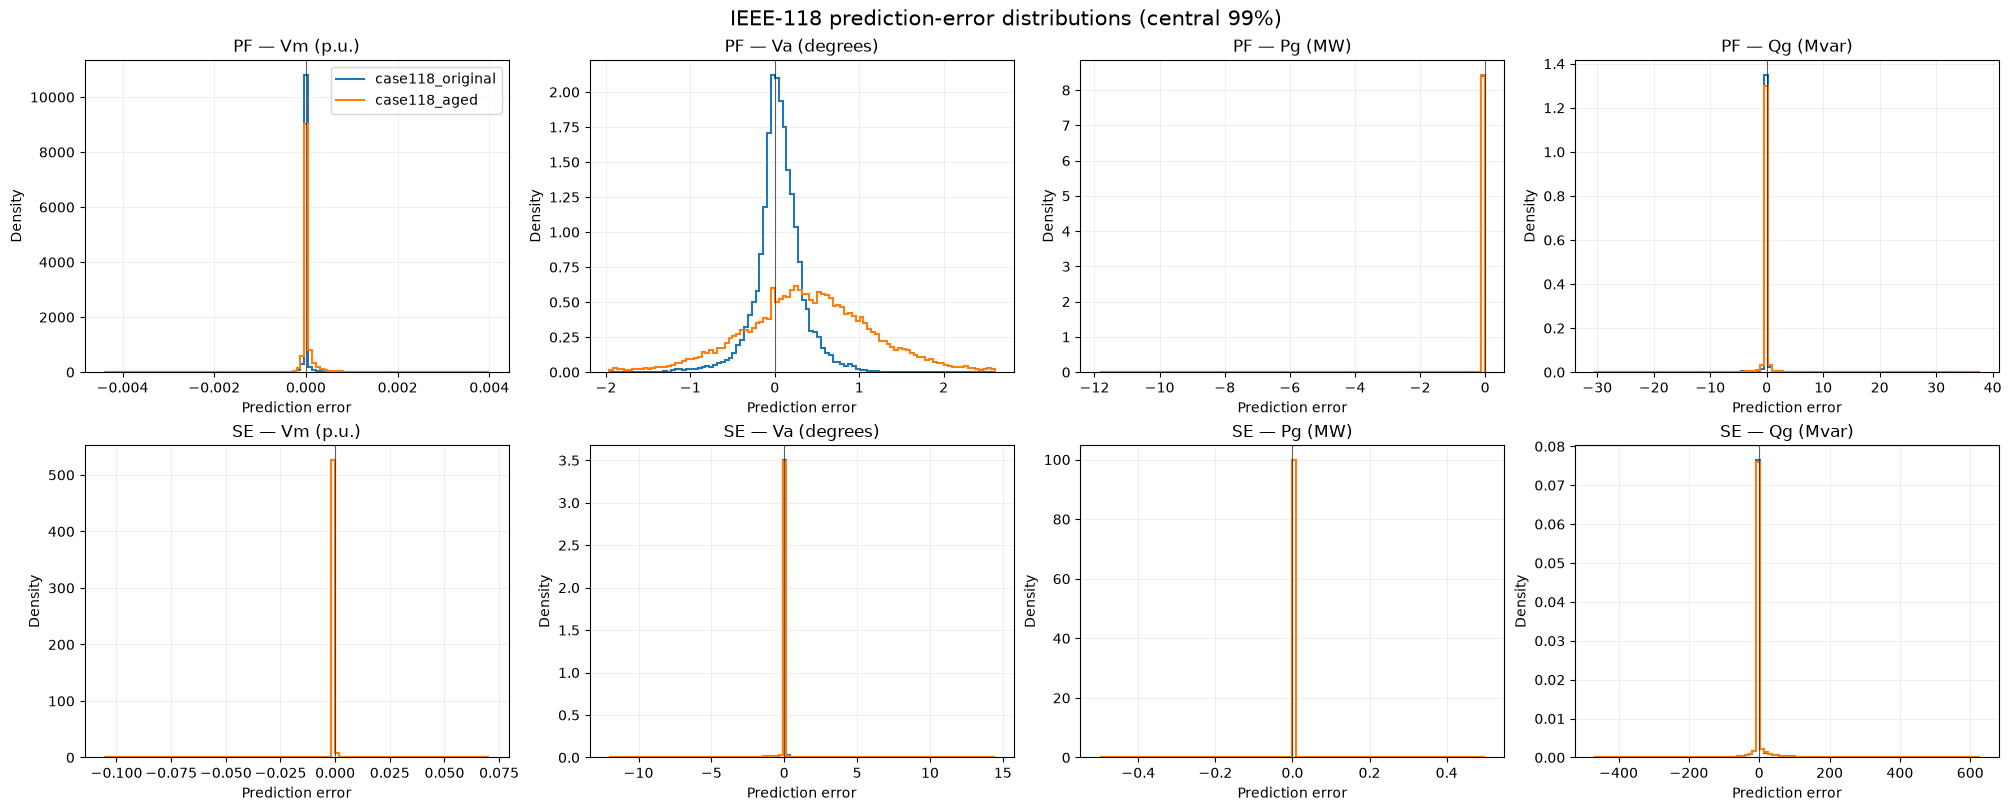

In [10]:
error_specs = {
    "Vm (p.u.)": ("vm_gt_pu", "vm_pred_pu"),
    "Va (degrees)": ("va_gt_deg", "va_pred_deg"),
    "Pg (MW)": ("pg_gt_mw", "pg_pred_mw"),
    "Qg (Mvar)": ("qg_gt_mvar", "qg_pred_mvar"),
}
colors = {"case118_original": "tab:blue", "case118_aged": "tab:orange"}
fig, axes = plt.subplots(2, 4, figsize=(20, 8), constrained_layout=True)

for row, task in enumerate(("pf", "se")):
    for col, (label, (gt_column, pred_column)) in enumerate(error_specs.items()):
        ax = axes[row, col]
        errors = {}
        for dataset_name in datasets:
            values = pd.read_parquet(
                output_paths[dataset_name, task],
                columns=[gt_column, pred_column],
            )
            error = (values[pred_column] - values[gt_column]).to_numpy()
            errors[dataset_name] = error[np.isfinite(error)]

        lower = min(np.quantile(error, 0.005) for error in errors.values())
        upper = max(np.quantile(error, 0.995) for error in errors.values())
        if lower == upper:
            lower, upper = lower - 0.5, upper + 0.5
        bins = np.linspace(lower, upper, 101)
        for dataset_name, error in errors.items():
            density, _ = np.histogram(error, bins=bins, density=True)
            ax.stairs(
                density,
                bins,
                label=dataset_name,
                color=colors[dataset_name],
                linewidth=1.5,
            )
        ax.axvline(0, color="black", linewidth=0.8, alpha=0.6)
        ax.set_title(f"{task.upper()} — {label}")
        ax.set_xlabel("Prediction error")
        ax.set_ylabel("Density")
        ax.grid(alpha=0.2)
        if row == 0 and col == 0:
            ax.legend()

histogram_path = OUTPUT_DIR / "error_histograms.png"
fig.suptitle("IEEE-118 prediction-error distributions (central 99%)", fontsize=15)
fig.savefig(histogram_path, dpi=200, bbox_inches="tight")
print(f"Saved histogram to {histogram_path}")
plt.show()

## 6. Hidden-aging experiment: aged state with original line impedance

This experiment represents an aged physical network whose changed line impedances are unknown to the operator. Bus/generator measurements, branch flows, and all ground-truth targets come from `case118_aged`, while the model receives the matched original network's line-admittance features. Graphkit does not feed raw `r` and `x` to the model; their effect is encoded by the four directional admittance columns `Yff`/`Yft` (and `Ytt`/`Ytf` on reverse edges), so only those normalized columns are replaced. Branch status, topology, limits, tap settings, and every measured or target quantity remain from the aged case.

Cases are paired by load-scenario ID and scenario signature (active branches/generators plus the randomized generator costs), rather than by dataset row number. Aged cases with no exact original counterpart are excluded and reported below. The final histogram compares the correctly specified aged run with the hidden-aging run on exactly the same retained scenarios.


In [11]:
ORIGINAL_NAME = "case118_original"
AGED_NAME = "case118_aged"
HIDDEN_AGING_NAME = "case118_aged_original_impedance"
original_dataset = datasets[ORIGINAL_NAME]
aged_dataset = datasets[AGED_NAME]
edge_type = ("bus", "connects", "bus")
admittance_columns = slice(YFF_TT_R, YFT_TF_I + 1)


def group_indices_by_load(dataset):
    groups = {}
    for index, load_index in enumerate(dataset.load_scenarios.tolist()):
        groups.setdefault(int(load_index), []).append(index)
    return groups


def scenario_signature(graph):
    branch_on = (graph[edge_type].edge_attr[:, B_ON] > 0.5).to(torch.uint8)
    generator_on = (graph["gen"].x[:, G_ON] > 0.5).to(torch.uint8)
    generator_cost = graph["gen"].x[:, C0_H : C2_H + 1]
    return (
        branch_on.cpu().numpy().tobytes(),
        generator_on.cpu().numpy().tobytes(),
        generator_cost.cpu().numpy().tobytes(),
    )


original_groups = group_indices_by_load(original_dataset)
aged_groups = group_indices_by_load(aged_dataset)
hidden_aging_pairs = {}


def match_in_order(aged_indices, original_indices):
    """Return the longest order-preserving match of scenario signatures."""
    aged_signatures = [scenario_signature(aged_dataset[i]) for i in aged_indices]
    original_signatures = [
        scenario_signature(original_dataset[i]) for i in original_indices
    ]
    n_aged, n_original = len(aged_indices), len(original_indices)
    lengths = np.zeros((n_aged + 1, n_original + 1), dtype=np.int8)
    for i in range(n_aged):
        for j in range(n_original):
            if aged_signatures[i] == original_signatures[j]:
                lengths[i + 1, j + 1] = lengths[i, j] + 1
            else:
                lengths[i + 1, j + 1] = max(lengths[i, j + 1], lengths[i + 1, j])
    pairs = {}
    i, j = n_aged, n_original
    while i and j:
        if aged_signatures[i - 1] == original_signatures[j - 1]:
            pairs[aged_indices[i - 1]] = original_indices[j - 1]
            i -= 1
            j -= 1
        elif lengths[i - 1, j] >= lengths[i, j - 1]:
            i -= 1
        else:
            j -= 1
    return pairs


for load_index, aged_indices in aged_groups.items():
    original_indices = original_groups.get(load_index, [])
    hidden_aging_pairs.update(match_in_order(aged_indices, original_indices))

hidden_aging_indices = sorted(hidden_aging_pairs)
excluded_count = len(aged_dataset) - len(hidden_aging_indices)
print(f"Matched {len(hidden_aging_indices):,} aged scenarios")
print(f"Excluded {excluded_count:,} aged scenarios without an original counterpart")

Matched 1,000 aged scenarios
Excluded 0 aged scenarios without an original counterpart


In [12]:
def prepare_hidden_aging_graph(dataset, aged_index, task):
    aged_graph = dataset[aged_index]
    original_index = hidden_aging_pairs[aged_index]
    original_graph = original_dataset[original_index]

    if not torch.equal(
        aged_graph[edge_type].edge_index, original_graph[edge_type].edge_index
    ):
        raise ValueError(f"Edge ordering differs for aged scenario {aged_index}")
    if scenario_signature(aged_graph) != scenario_signature(original_graph):
        raise ValueError(f"Scenario pairing differs for aged scenario {aged_index}")
    if not np.isclose(float(aged_graph.baseMVA), float(original_graph.baseMVA)):
        raise ValueError(f"baseMVA differs for aged scenario {aged_index}")

    # Both graphs are already normalized with the same saved normalizer.
    # Replace only the impedance-derived model inputs; retain all aged targets.
    aged_graph[edge_type].edge_attr[:, admittance_columns] = original_graph[
        edge_type
    ].edge_attr[:, admittance_columns]
    return apply_task_transform(aged_graph, aged_index, task)


hidden_aging_paths = {}
for task in ("pf", "se"):
    output_path = (
        OUTPUT_DIR / f"{HIDDEN_AGING_NAME}_{task}_ground_truth_predictions.parquet"
    )
    if output_path.exists():
        print(f"Reusing existing output: {output_path}")
    else:
        output_path = predict_all(
            HIDDEN_AGING_NAME,
            aged_dataset,
            task,
            indices=hidden_aging_indices,
            graph_preparer=prepare_hidden_aging_graph,
        )
    hidden_aging_paths[HIDDEN_AGING_NAME, task] = output_path
output_paths.update(hidden_aging_paths)
print(f"Successfully evaluated {len(hidden_aging_indices):,} matched scenarios")

Reusing existing output: results/local_predictions/case118_aged_original_impedance_pf_ground_truth_predictions.parquet
Reusing existing output: results/local_predictions/case118_aged_original_impedance_se_ground_truth_predictions.parquet
Successfully evaluated 1,000 matched scenarios


Saved histogram to results/local_predictions/hidden_aging_error_histograms.png


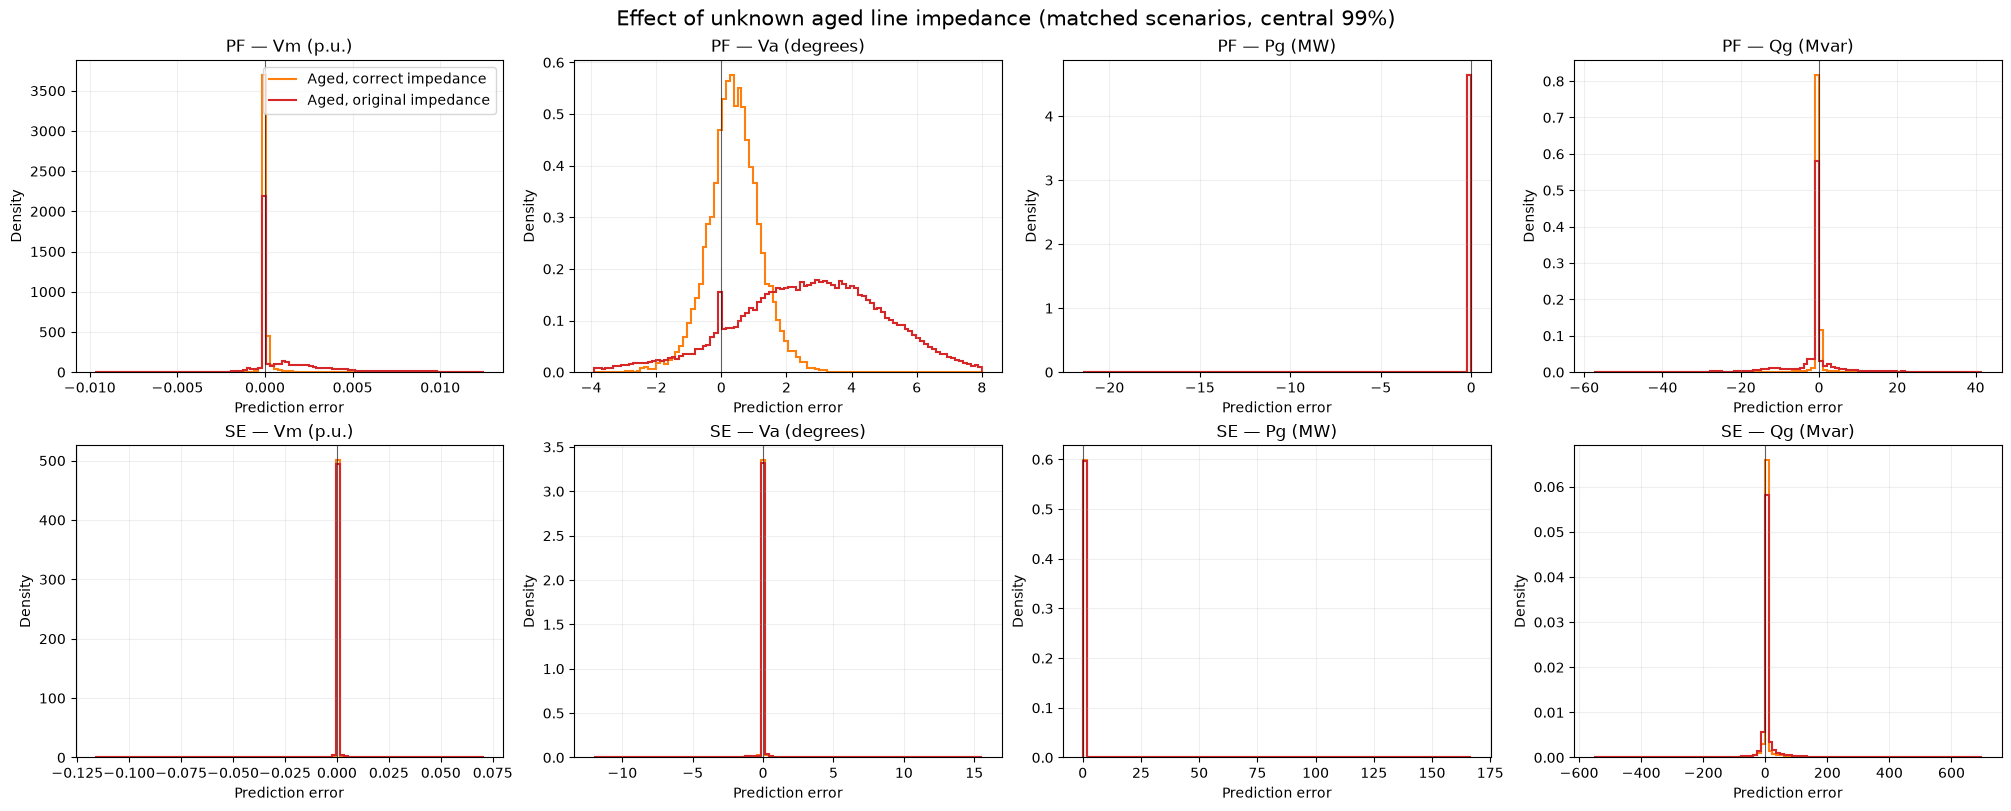

In [13]:
comparison_colors = {
    "Aged, correct impedance": "tab:orange",
    "Aged, original impedance": "tab:red",
}
fig, axes = plt.subplots(2, 4, figsize=(20, 8), constrained_layout=True)
retained_indices = set(hidden_aging_indices)

for row, task in enumerate(("pf", "se")):
    for col, (label, (gt_column, pred_column)) in enumerate(error_specs.items()):
        columns = key_columns + [gt_column, pred_column]
        aged_known = pd.read_parquet(output_paths[AGED_NAME, task], columns=columns)
        aged_known = aged_known[aged_known["dataset_index"].isin(retained_indices)]
        aged_hidden = pd.read_parquet(
            output_paths[HIDDEN_AGING_NAME, task], columns=columns
        )
        aged_known = aged_known.reset_index(drop=True)
        aged_hidden = aged_hidden.reset_index(drop=True)
        if not aged_known[key_columns].equals(aged_hidden[key_columns]):
            raise ValueError(f"Comparison row keys differ for {task} {label}")
        if not np.allclose(aged_known[gt_column], aged_hidden[gt_column]):
            raise ValueError(f"Ground truths differ for {task} {label}")

        errors = {
            "Aged, correct impedance": (
                aged_known[pred_column] - aged_known[gt_column]
            ).to_numpy(),
            "Aged, original impedance": (
                aged_hidden[pred_column] - aged_hidden[gt_column]
            ).to_numpy(),
        }
        errors = {name: values[np.isfinite(values)] for name, values in errors.items()}
        lower = min(np.quantile(error, 0.005) for error in errors.values())
        upper = max(np.quantile(error, 0.995) for error in errors.values())
        if lower == upper:
            lower, upper = lower - 0.5, upper + 0.5
        bins = np.linspace(lower, upper, 101)
        ax = axes[row, col]
        for name, error in errors.items():
            density, _ = np.histogram(error, bins=bins, density=True)
            ax.stairs(
                density, bins, label=name, color=comparison_colors[name], linewidth=1.5
            )
        ax.axvline(0, color="black", linewidth=0.8, alpha=0.6)
        ax.set_title(f"{task.upper()} — {label}")
        ax.set_xlabel("Prediction error")
        ax.set_ylabel("Density")
        ax.grid(alpha=0.2)
        if row == 0 and col == 0:
            ax.legend(loc="upper right")

hidden_histogram_path = OUTPUT_DIR / "hidden_aging_error_histograms.png"
fig.suptitle(
    "Effect of unknown aged line impedance (matched scenarios, central 99%)",
    fontsize=15,
)
fig.savefig(hidden_histogram_path, dpi=200, bbox_inches="tight")
print(f"Saved histogram to {hidden_histogram_path}")
plt.show()

7. Use GENCO to improve the estimate of the aged lines

A well known method of noise suppression of the sample is to use gradient-based denoising. Our prior is that our input line impedance are noisy because of aging of the lines. This phenomena caused a shift/drift in network's line impedance, and it corrupted our admittance matrix. Now, I want to try to recover/retrieve the shifted Y-matrix, using the GENCO model. I want to fix the model parameters, back propagate the error, and shift the inputs for a little bit each time in a direction that minimizes the GENCO model error. This process should be done over lots of samples of the data we collected using aged line impedances.

The code below assumes the aged Y-matrix is unknown but an estimate of the original impedance exists. It optimizes dimensionless R/X multipliers instead of raw per-unit values, accumulates an exact full-dataset mean gradient, and takes one projected Adam step per epoch. Multipliers are bounded by the same 1.0--1.5 range used to generate the synthetic ageing, which prevents low-impedance lines from dominating the update.

During the iterative denoising process, plot the these quantities using tensorboard in a folder named `tb`:

1- impedance mismatch = actual aged line impedance - current estimated line impedance (diagnostic only)

2- model RMSE = error on the checkpoint's masked Vm/Va reconstruction target using the current line impedance


In [ ]:
import re
from datetime import datetime

from torch.nn import functional as F

from torch.utils.tensorboard import SummaryWriter

# Optimize physical line resistance/reactance over every available aged scenario.
EPOCHS = 20
LR = 1e-2
MULTIPLIER_MIN = 1.0
MULTIPLIER_MAX = 1.5
TB_RUN_NAME = datetime.now().strftime("impedance-multiplier-denoising-%Y%m%d-%H%M%S")
TB_DIR = PROJECT_DIR / "tb" / TB_RUN_NAME
DENOISED_Y_PATH = OUTPUT_DIR / "denoised_admittance.pt"


def available_dataset_indices(dataset):
    """Return actual saved scenario IDs, including datasets with solver gaps."""
    prefix = "data_index_"
    return sorted(
        int(path.stem.removeprefix(prefix))
        for path in Path(dataset.processed_dir).glob(f"{prefix}*.pt")
    )


training_indices = available_dataset_indices(aged_dataset)
original_training_indices = available_dataset_indices(original_dataset)
if not training_indices:
    raise RuntimeError("The aged dataset contains no scenarios")
if not original_training_indices:
    raise RuntimeError("The original dataset contains no scenarios")

# Every untransformed scenario has the same complete directed-edge ordering. The
# first half stores from->to edges and the second half their to->from counterparts.
reference_graph = aged_dataset.get(training_indices[0])
reference_edge_index = reference_graph[edge_type].edge_index.clone()
n_directed_edges = reference_edge_index.size(1)
n_lines = n_directed_edges // 2
if not torch.equal(
    reference_edge_index[:, :n_lines],
    reference_edge_index.flip(0)[:, n_lines:],
):
    raise ValueError("Forward and reverse branch ordering is not aligned")


def mean_admittance(dataset, indices, description):
    """Average Y only while each directed branch is in service."""
    total = torch.zeros((n_directed_edges, 4), dtype=torch.float64)
    total_squared = torch.zeros_like(total)
    active_count = torch.zeros(n_directed_edges, dtype=torch.float64)
    for index in tqdm(indices, desc=description):
        graph = dataset.get(index)
        if not torch.equal(graph[edge_type].edge_index, reference_edge_index):
            raise ValueError(f"Full edge ordering differs for dataset index {index}")
        edge_attr = graph[edge_type].edge_attr
        values = edge_attr[:, admittance_columns].double()
        active = edge_attr[:, B_ON] > 0.5
        total[active] += values[active]
        total_squared[active] += values[active].square()
        active_count[active] += 1
    if (active_count == 0).any():
        missing = (active_count == 0).nonzero(as_tuple=False).flatten().tolist()
        raise RuntimeError(f"Directed branches never observed in service: {missing}")
    mean = total / active_count[:, None]
    variance = (total_squared / active_count[:, None] - mean.square()).clamp_min(0)
    return mean.float(), variance.sqrt().float()


# Average only active observations: random outages encode the disconnected line's
# Y as zero, which is topology state rather than a different line impedance.
initial_admittance, original_admittance_std = mean_admittance(
    original_dataset,
    original_training_indices,
    "Averaging original Y",
)
actual_aged_admittance, aged_admittance_std = mean_admittance(
    aged_dataset,
    training_indices,
    "Averaging aged Y (diagnostic only)",
)

# Datakit normalizes Y by baseMVA_orig/baseMVA. For an ordinary line,
# Yft = -1/(R+jX), so R+jX = scale/(-Yft_normalized).
admittance_scale = float(normalizer.baseMVA_orig / normalizer.baseMVA)
initial_self_forward = torch.complex(
    initial_admittance[:n_lines, 0],
    initial_admittance[:n_lines, 1],
)
initial_cross_forward = torch.complex(
    initial_admittance[:n_lines, 2],
    initial_admittance[:n_lines, 3],
)
initial_self_reverse = torch.complex(
    initial_admittance[n_lines:, 0],
    initial_admittance[n_lines:, 1],
)
initial_cross_reverse = torch.complex(
    initial_admittance[n_lines:, 2],
    initial_admittance[n_lines:, 3],
)
initial_series_y = -initial_cross_forward
initial_impedance = admittance_scale / initial_series_y
forward_shunt = initial_self_forward - initial_series_y
reverse_shunt = initial_self_reverse - initial_series_y

# Use the same authoritative eligibility rule as create_aged_network.py: only
# in-service, non-transformer MATPOWER branches may have ageing-related R/X changes.
original_case_path = PROJECT_DIR / "grids" / "case118_original.m"
original_case_text = original_case_path.read_text()
branch_match = re.search(
    r"mpc\.branch\s*=\s*\[(.*?)\];",
    original_case_text,
    re.DOTALL,
)

branch_fields = []
for line in branch_match.group(1).splitlines():
    fields = line.partition("%")[0].strip().rstrip(";").split()
    if fields:
        branch_fields.append(fields)
if len(branch_fields) != n_lines:
    raise ValueError(
        f"MATPOWER has {len(branch_fields)} branches but GraphKit has {n_lines}"
    )
learnable_line_mask = torch.tensor(
    [
        float(fields[10]) > 0
        and not (
            (float(fields[8]) != 0.0 and float(fields[8]) != 1.0)
            or float(fields[9]) != 0.0
        )
        for fields in branch_fields
    ],
    dtype=torch.bool,
)
if not learnable_line_mask.any():
    raise RuntimeError("No in-service non-transformer lines are available")
learnable_directed_mask = torch.cat([learnable_line_mask, learnable_line_mask])

initial_resistance = initial_impedance.real.float()
initial_reactance = initial_impedance.imag.float()
resistance_multiplier = torch.nn.Parameter(torch.ones_like(initial_resistance))
reactance_multiplier = torch.nn.Parameter(torch.ones_like(initial_reactance))
multiplier_parameters = [resistance_multiplier, reactance_multiplier]
optimizer = torch.optim.Adam(multiplier_parameters, lr=LR)


def estimated_impedance_components():
    """Map dimensionless ageing multipliers to per-unit R/X."""
    return (
        initial_resistance * resistance_multiplier,
        initial_reactance * reactance_multiplier,
    )


def impedance_from_admittance(admittance):
    """Recover ordinary-line R/X from normalized forward transfer admittance."""
    cross = torch.complex(admittance[:n_lines, 2], admittance[:n_lines, 3])
    return admittance_scale / (-cross)


actual_aged_impedance = impedance_from_admittance(actual_aged_admittance)
actual_aged_resistance = actual_aged_impedance.real
actual_aged_reactance = actual_aged_impedance.imag


def admittance_from_estimated_impedance():
    """Differentiably convert bounded R/X multipliers to normalized Y inputs."""
    estimated_resistance, estimated_reactance = estimated_impedance_components()
    impedance = torch.complex(estimated_resistance, estimated_reactance)
    series_y = admittance_scale / impedance
    estimated = initial_admittance.clone()

    forward_values = torch.stack(
        [
            (series_y + forward_shunt).real,
            (series_y + forward_shunt).imag,
            -series_y.real,
            -series_y.imag,
        ],
        dim=1,
    )
    reverse_values = torch.stack(
        [
            (series_y + reverse_shunt).real,
            (series_y + reverse_shunt).imag,
            -series_y.real,
            -series_y.imag,
        ],
        dim=1,
    )
    estimated[:n_lines][learnable_line_mask] = forward_values[learnable_line_mask]
    estimated[n_lines:][learnable_line_mask] = reverse_values[learnable_line_mask]
    return estimated


# Freeze GENCO. Gradients pass through it to R/X, but model weights never update.
model.eval()
for parameter in model.parameters():
    parameter.requires_grad_(False)


def prepare_denoising_graph(aged_index, estimated_admittance):
    """Insert the shared estimated line Y values, then apply the standard PF mask."""
    graph = aged_dataset.get(aged_index)
    if not torch.equal(graph[edge_type].edge_index, reference_edge_index):
        raise ValueError(f"Full edge ordering differs for aged index {aged_index}")
    edge_attr = graph[edge_type].edge_attr.clone()
    current_y = edge_attr[:, admittance_columns].clone()
    current_y[learnable_directed_mask] = estimated_admittance[learnable_directed_mask]
    edge_attr[:, admittance_columns] = current_y
    graph[edge_type].edge_attr = edge_attr
    return apply_task_transform(graph, aged_index, "pf")


def masked_pf_model_loss(batch, output):
    """The checkpoint's MaskedBusMSE: masked Vm/Va in normalized space."""
    target = batch["bus"].y[:, [VM_H, VA_H]]
    prediction = output["bus"][:, [VM_OUT, VA_OUT]]
    supervised_mask = batch.mask_dict["bus"][:, [VM_H, VA_H]]
    target_count = int(supervised_mask.sum().item())
    return (
        F.mse_loss(prediction[supervised_mask], target[supervised_mask]),
        target_count,
    )


def evaluate_model_mse(indices, description):
    """Evaluate one fixed R/X state over all requested scenarios."""
    loss_sum = 0.0
    target_count = 0
    with torch.no_grad():
        for start in tqdm(
            range(0, len(indices), BATCH_SIZE), desc=description, leave=False
        ):
            batch_indices = indices[start : start + BATCH_SIZE]
            current_admittance = admittance_from_estimated_impedance()
            graphs = [
                prepare_denoising_graph(index, current_admittance)
                for index in batch_indices
            ]
            batch = Batch.from_data_list(graphs).to(DEVICE)
            model_loss, batch_target_count = masked_pf_model_loss(batch, model(batch))
            loss_sum += model_loss.item() * batch_target_count
            target_count += batch_target_count
    return loss_sum / target_count


def impedance_metrics():
    """Return diagnostic errors without exposing aged Y to optimization."""
    estimated_resistance, estimated_reactance = estimated_impedance_components()
    resistance_mismatch = (actual_aged_resistance - estimated_resistance.detach())[
        learnable_line_mask
    ]
    reactance_mismatch = (actual_aged_reactance - estimated_reactance.detach())[
        learnable_line_mask
    ]
    combined = torch.cat([resistance_mismatch, reactance_mismatch])
    return resistance_mismatch, reactance_mismatch, combined


def log_epoch_metrics(writer, step, model_mse, gradient_norms=None):
    resistance_mismatch, reactance_mismatch, combined = impedance_metrics()
    resistance_values = resistance_multiplier.detach()[learnable_line_mask]
    reactance_values = reactance_multiplier.detach()[learnable_line_mask]
    mismatch_mae = combined.abs().mean().item()
    mismatch_rmse = combined.square().mean().sqrt().item()
    model_rmse = model_mse**0.5
    writer.add_scalar("epoch/model_mse", model_mse, step)
    writer.add_scalar("epoch/model_rmse", model_rmse, step)
    writer.add_scalar("epoch/impedance_mismatch_mae", mismatch_mae, step)
    writer.add_scalar("epoch/impedance_mismatch_rmse", mismatch_rmse, step)
    writer.add_scalar(
        "epoch/resistance_mismatch_rmse",
        resistance_mismatch.square().mean().sqrt().item(),
        step,
    )
    writer.add_scalar(
        "epoch/reactance_mismatch_rmse",
        reactance_mismatch.square().mean().sqrt().item(),
        step,
    )
    writer.add_histogram("epoch/resistance_mismatch", resistance_mismatch, step)
    writer.add_histogram("epoch/reactance_mismatch", reactance_mismatch, step)
    writer.add_histogram("epoch/resistance_multiplier", resistance_values, step)
    writer.add_histogram("epoch/reactance_multiplier", reactance_values, step)
    for name, values in (
        ("resistance", resistance_values),
        ("reactance", reactance_values),
    ):
        writer.add_scalar(f"epoch/{name}_multiplier_median", values.median().item(), step)
        writer.add_scalar(f"epoch/{name}_multiplier_max", values.max().item(), step)
        writer.add_scalar(
            f"epoch/{name}_multiplier_at_upper_bound_fraction",
            (values >= MULTIPLIER_MAX - 1e-6).float().mean().item(),
            step,
        )
    writer.add_scalar("epoch/learning_rate", optimizer.param_groups[0]["lr"], step)
    if gradient_norms is not None:
        writer.add_scalar("epoch/resistance_multiplier_gradient_norm", gradient_norms[0], step)
        writer.add_scalar("epoch/reactance_multiplier_gradient_norm", gradient_norms[1], step)
    writer.flush()
    return (
        model_rmse,
        mismatch_mae,
        mismatch_rmse,
        resistance_values.median().item(),
        reactance_values.median().item(),
        resistance_values.max().item(),
        reactance_values.max().item(),
    )


writer = SummaryWriter(log_dir=str(TB_DIR))
try:
    last_model_mse = None
    for epoch in range(EPOCHS):
        epoch_generator = torch.Generator().manual_seed(SEED + epoch)
        order = torch.randperm(
            len(training_indices),
            generator=epoch_generator,
        ).tolist()
        epoch_loss_sum = 0.0
        epoch_target_count = 0
        optimizer.zero_grad(set_to_none=True)

        progress = tqdm(
            range(0, len(order), BATCH_SIZE),
            desc=f"Multiplier R/X epoch {epoch + 1}/{EPOCHS}",
        )
        for start in progress:
            positions = order[start : start + BATCH_SIZE]
            batch_indices = [training_indices[position] for position in positions]
            current_admittance = admittance_from_estimated_impedance()
            graphs = [
                prepare_denoising_graph(index, current_admittance)
                for index in batch_indices
            ]
            batch = Batch.from_data_list(graphs).to(DEVICE)

            output = model(batch)
            model_loss, target_count = masked_pf_model_loss(batch, output)
            # Accumulate the exact full-dataset mean gradient. Stepping here would
            # apply LR once per mini-batch and make the result batch-size dependent.
            (model_loss * target_count).backward()

            epoch_loss_sum += model_loss.item() * target_count
            epoch_target_count += target_count
            progress.set_postfix(model_mse=f"{model_loss.item():.3e}")

        epoch_model_mse = epoch_loss_sum / epoch_target_count
        gradient_norms = []
        for parameter in multiplier_parameters:
            if parameter.grad is None:
                raise RuntimeError("GENCO did not propagate gradients to R/X multipliers")
            parameter.grad.div_(epoch_target_count)
            parameter.grad[~learnable_line_mask] = 0.0
            if not torch.isfinite(parameter.grad).all():
                raise RuntimeError("Non-finite R/X multiplier gradient")
            gradient_norms.append(parameter.grad[learnable_line_mask].norm().item())
        if epoch == 0:
            log_epoch_metrics(writer, 0, epoch_model_mse)

        optimizer.step()
        with torch.no_grad():
            for parameter in multiplier_parameters:
                parameter.clamp_(MULTIPLIER_MIN, MULTIPLIER_MAX)
                parameter[~learnable_line_mask] = 1.0

        candidate_mse = evaluate_model_mse(
            training_indices,
            f"Checking multiplier epoch {epoch + 1}",
        )
        last_model_mse = candidate_mse
        (
            model_rmse,
            mismatch_mae,
            mismatch_rmse,
            resistance_median,
            reactance_median,
            resistance_max,
            reactance_max,
        ) = log_epoch_metrics(
            writer, epoch + 1, candidate_mse, gradient_norms
        )
        print(
            f"Epoch {epoch + 1:02d}: model RMSE={model_rmse:.6e}, "
            f"R/X mismatch MAE={mismatch_mae:.6e}, "
            f"R/X mismatch RMSE={mismatch_rmse:.6e}, "
            f"median multipliers=({resistance_median:.4f}, {reactance_median:.4f}), "
            f"max multipliers=({resistance_max:.4f}, {reactance_max:.4f})"
        )
finally:
    writer.close()

estimated_resistance, estimated_reactance = estimated_impedance_components()
final_admittance = admittance_from_estimated_impedance().detach().cpu()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
torch.save(
    {
        "edge_index": reference_edge_index,
        "learnable_line_mask": learnable_line_mask,
        "estimated_resistance_pu": estimated_resistance.detach().cpu(),
        "estimated_reactance_pu": estimated_reactance.detach().cpu(),
        "estimated_resistance_multiplier": resistance_multiplier.detach().cpu(),
        "estimated_reactance_multiplier": reactance_multiplier.detach().cpu(),
        "initial_resistance_pu": initial_resistance,
        "initial_reactance_pu": initial_reactance,
        "actual_aged_resistance_pu": actual_aged_resistance,
        "actual_aged_reactance_pu": actual_aged_reactance,
        "estimated_admittance_normalized": final_admittance,
        "initial_admittance_normalized": initial_admittance,
        "actual_aged_admittance_normalized": actual_aged_admittance,
        "original_scenario_std": original_admittance_std,
        "aged_scenario_std": aged_admittance_std,
        "training_indices": torch.as_tensor(training_indices),
        "epochs": EPOCHS,
        "learning_rate": LR,
        "optimizer": "Adam",
        "multiplier_bounds": (MULTIPLIER_MIN, MULTIPLIER_MAX),
        "constraint": "R and X are initial values times bounded ageing multipliers",
    },
    DENOISED_Y_PATH,
)
print(f"Optimized {int(learnable_line_mask.sum()):,} non-transformer lines")
print(f"Saved bounded multiplier-space R/X and recovered Y to {DENOISED_Y_PATH}")
print(f"TensorBoard logs: {TB_DIR}")
print(f"Launch with: tensorboard --logdir {TB_DIR}")

Averaging original Y:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging aged Y (diagnostic only):   0%|          | 0/1000 [00:00<?, ?it/s]

Constrained R/X epoch 1/20:   0%|          | 0/63 [00:00<?, ?it/s]

Checking epoch 1 step 1:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 01: model RMSE=3.776465e-02, R/X mismatch MAE=1.690093e-02, R/X mismatch RMSE=2.931866e-02, accepted step=1.000e-01


...

Checking epoch 19 step 1:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 19: model RMSE=2.570336e-02, R/X mismatch MAE=1.674436e-02, R/X mismatch RMSE=2.912841e-02, accepted step=1.000e-01


Constrained R/X epoch 20/20:   0%|          | 0/63 [00:00<?, ?it/s]

Checking epoch 20 step 1:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 20: model RMSE=2.558173e-02, R/X mismatch MAE=1.673463e-02, R/X mismatch RMSE=2.911993e-02, accepted step=1.000e-01
Optimized 177 non-transformer lines
Saved constrained R/X and recovered Y to results/local_predictions/denoised_admittance.pt
TensorBoard logs: tb/impedance-denoising-20261019-025901
Launch with: tensorboard --logdir tb/impedance-denoising-20261019-025901


Saved plot to results/local_predictions/resistance_comparison.png


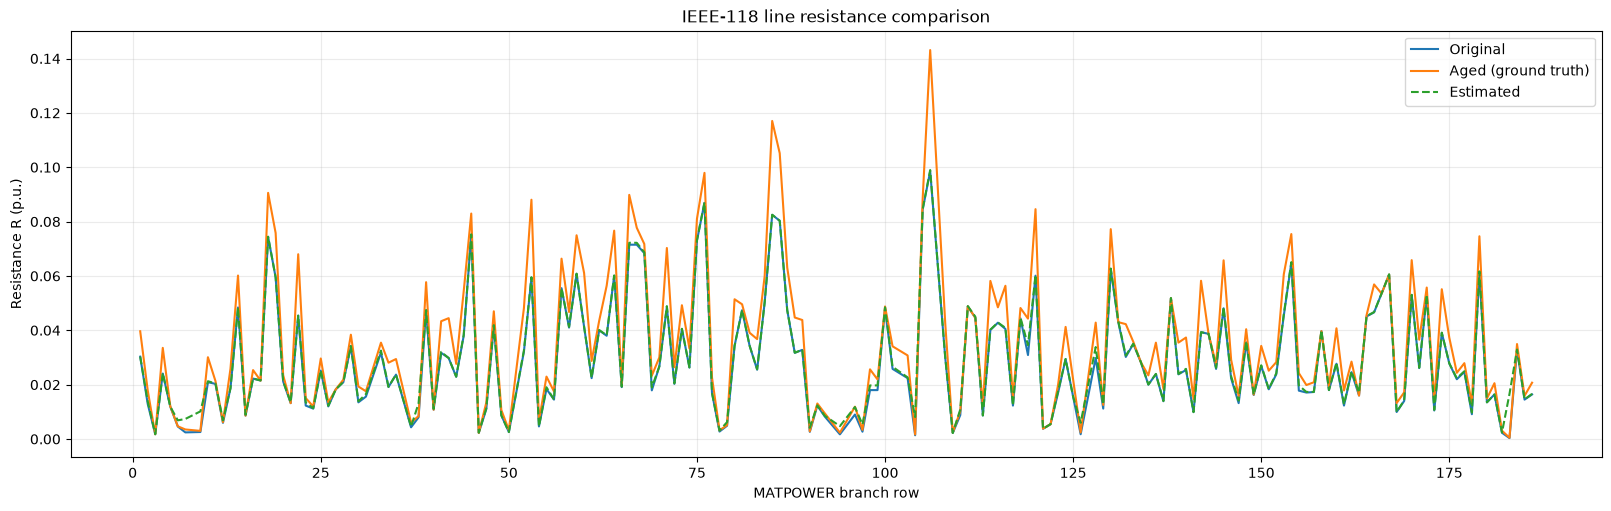

Saved plot to results/local_predictions/reactance_comparison.png


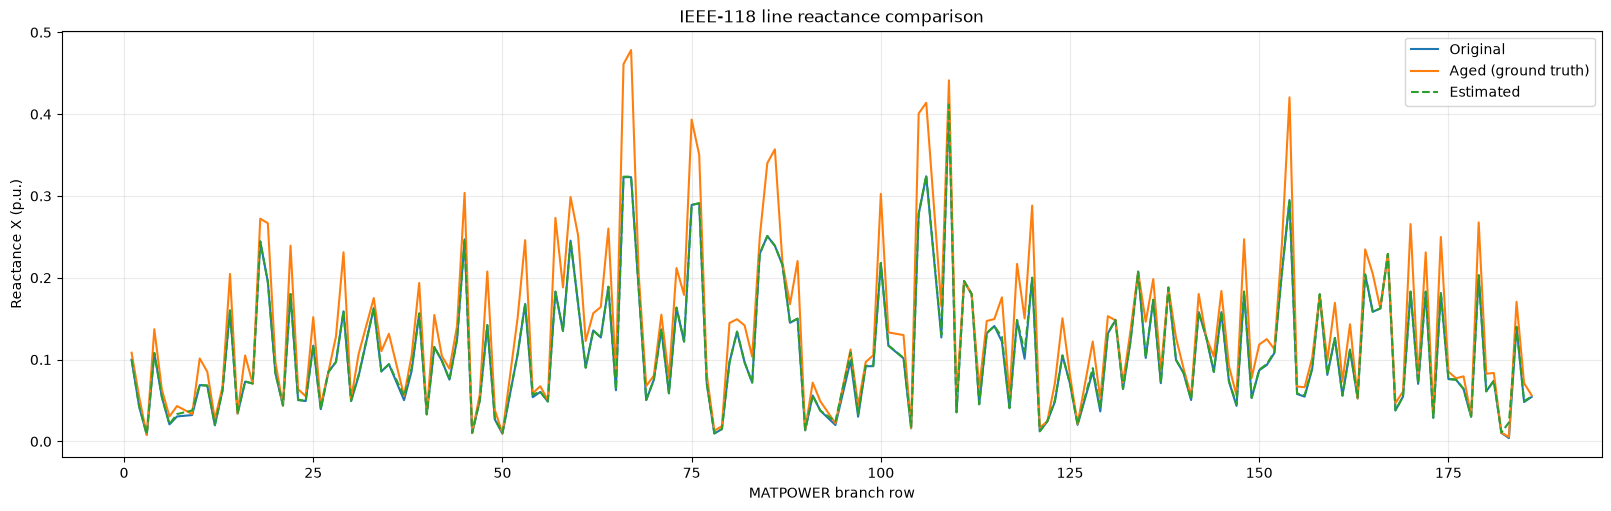

In [15]:
# Compare the original, true aged, and GENCO-estimated line impedances.
impedance_result = torch.load(
    DENOISED_Y_PATH,
    map_location="cpu",
    weights_only=True,
)
plot_mask = impedance_result["learnable_line_mask"].bool()
branch_rows = torch.arange(1, plot_mask.numel() + 1)[plot_mask].numpy()


def plot_impedance_component(component, ylabel, output_name):
    original = impedance_result[f"initial_{component}_pu"][plot_mask].numpy()
    aged = impedance_result[f"actual_aged_{component}_pu"][plot_mask].numpy()
    estimated = impedance_result[f"estimated_{component}_pu"][plot_mask].numpy()

    fig, ax = plt.subplots(figsize=(16, 5), constrained_layout=True)
    ax.plot(branch_rows, original, label="Original", color="tab:blue", linewidth=1.5)
    ax.plot(
        branch_rows,
        aged,
        label="Aged (ground truth)",
        color="tab:orange",
        linewidth=1.5,
    )
    ax.plot(
        branch_rows,
        estimated,
        label="Estimated",
        color="tab:green",
        linewidth=1.5,
        linestyle="--",
    )
    ax.set_title(f"IEEE-118 line {component} comparison")
    ax.set_xlabel("MATPOWER branch row")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend()

    output_path = OUTPUT_DIR / output_name
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    print(f"Saved plot to {output_path}")
    plt.show()


plot_impedance_component(
    "resistance",
    "Resistance R (p.u.)",
    "resistance_comparison.png",
)
plot_impedance_component(
    "reactance",
    "Reactance X (p.u.)",
    "reactance_comparison.png",
)